<a href="https://colab.research.google.com/github/Anggasaputraramadhan/PCVK/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODUL 6 - FILTER SPASIAL (Low Pass Filter, High Pass Filter, Point Detection, Line Detection, Edge Detection)
A. TUJUAN
   - Mahasiswa mampu memahami konsep Filter Spasial.
   - Mahasiswa dapat mengetahui beberapa jenis Filter Spasial
   - Mahasiswa dapat membuat filter sederhana menggunakan filter
   - Kernel yang tersedia dan melakukan perhitungan konvolusi.
B. ALAT DAN BAHAN
   - PC/Laptop
   - Github
   - Google Colaborator

C. ULASAN TEORI

  C.1. Proses Filter
   Secara umum, proses filter sebuah citra adalah mekanisme untuk mengubah sinyal optis, elektronis, atau digital sesuai kriteria tertentu guna mengekstraksi bagian data yang diinginkan dan menghilangkan bagian yang tidak diinginkan. Tujuannya adalah membuat citra tampak lebih baik atau lebih jelas untuk dianalisis. Filter pada citra digunakan untuk:
   1. Menekan frekuensi tinggi pada citra, memperhalus citra (smoothing).
   2. Menekan frekuensi rendah seperti memperjelas atau mendeteksi tepi pada citra.
   Pemfilteran citra dapat dilakukan melalui dua domain:
   - Domain Frekuensi: Mengubah citra ke domain frekuensi,  mengalikannya dengan fungsi filter frekuensi, lalu mentransformasikannya kembali ke ruang spasial. Contohnya Low Pass Filter yang meloloskan frekuensi rendah (menghasilkan citra blur)
   - Domain Spasial: Manipulasi kumpulan piksel citra secara langsung untuk menghasilkan citra baru. Dilakukan melalui konvolusi citra input $f(i,j)$ dengan fungsi filter $h(i,j)$ yang disimulasikan dalam bentuk kernel diskret:

                        $$g(i,j) = h(i,j) \odot f(i,j)$$

  C.2. Proses Konvolusi
Konvolusi adalah penjumlahan dari perkalian setiap titik pada kernel dengan setiap titik pada fungsi masukan. Kernel bergeser pada fungsi masukan menggunakan konsep piksel tetangga (neighbouring pixels). Konsep tetangga meliputi 4-tetangga +, 4-tetangga x, dan 8-tetangga.

Secara matematis 2D, konvolusi dinyatakan sebagai:
$$g(x,y) = f(x,y) \Theta h(x,y) = \sum_{a=-\infty}^{\infty} \sum_{b=-\infty}^{\infty} f(a,b) g(x-a, y-b)$$

Masalah Efek Menggantung (Border Effect):
Saat memproses piksel pinggir, beberapa koefisien kernel tidak memiliki pasangan piksel di citra. Solusi penanganannya meliputi:
1. Piksel pinggir diabaikan (tidak dikonvolusi, nilainya tetap seperti asal).
2. Duplikasi elemen piksel pinggir.
3. Diasumsikan bernilai 0 atau konstanta lain.

Pseudocode Konvolusi:


In [1]:
import numpy as np

def konvolusi_manual_fix(image, mask):
    h, w = image.shape
    kh, kw = mask.shape
    image_result = np.zeros((h, w), dtype=np.float32)

    for i in range(1, h - 1):
        for j in range(1, w - 1):
            val = (
                image[i-1, j-1] * mask[0, 0] + image[i-1, j] * mask[0, 1] + image[i-1, j+1] * mask[0, 2] +
                image[i,   j-1] * mask[1, 0] + image[i,   j] * mask[1, 1] + image[i,   j+1] * mask[1, 2] +
                image[i+1, j-1] * mask[2, 0] + image[i+1, j] * mask[2, 1] + image[i+1, j+1] * mask[2, 2]
            )
            image_result[i, j] = val

    image_result = np.clip(image_result, 0, 255)
    return image_result.astype(np.uint8)

C.3. Jenis Filter Spasial
1. Sharpening (Penajaman): Memperkuat intensitas piksel pusat dibandingkan tetangganya.

Contoh Kernel:
$\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$ atau $\begin{bmatrix} 1 & 1 & 1 \\ 1 & -8 & 1 \\ 1 & 1 & 1 \end{bmatrix}$

2. Blurring (Pengaburan): Membuat nilai piksel pusat mendekati tetangganya.

Contoh: Gaussian Blurring $\frac{1}{16}\begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$

3. Emboss: Memperkuat tepi pada satu arah tertentu.
4. Filter Dasar Lainnya: Average Filter ($3\times3$), Low Pass Filter, High Pass Filter, Point Detection, Line Detection (Horizontal, Vertikal, $+45^\circ$, $-45^\circ$), serta Edge Detection (Roberts, Prewitt, Sobel).

D. PRAKTIKUM FILTER

Langkah Persiapan dan Konvolusi Tanpa Library
1. Buat notebook baru bernama Week7.ipynb di Google Colab dan simpan salinannya ke GitHub.
2. Import library dan hubungkan Google Drive:

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

Mounted at /content/drive


1. Membuat fungsi konvolusi manual (tanpa library OpenCV filter2D):

In [3]:
def convolution2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, padding, mode='constant', constant_values=0)
    h, w = image.shape
    kh, kw = kernel.shape
    oh = int((h - kh) / stride) + 1
    ow = int((w - kw) / stride) + 1
    output = np.zeros((oh, ow), dtype=np.float32)

    for y in range(oh):
        for x in range(ow):
            region = image[y*stride:y*stride+kh, x*stride:x*stride+kw]
            output[y, x] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)

2. Load citra dan uji coba konvolusi manual:

In [4]:
import cv2 as cv
import numpy as np
import os

file_path = '/content/drive/MyDrive/Polinema/Kuliah/PCVK/Images/mandrill.tiff'

if not os.path.exists(file_path):
    print(f"Peringatan: Berkas di path '{file_path}' tidak ditemukan.")
    print("Silakan sesuaikan path direktori Anda atau gunakan citra pengganti sementara.")
    img = np.zeros((512, 512, 3), dtype=np.uint8)
    cv.putText(img, "MANDRILL TEST", (100, 256), cv.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
else:
    img = cv.imread(file_path)
if img is not None:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
else:
    raise ValueError("Gagal membaca atau memuat citra.")
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

def convolution2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, padding, mode='constant', constant_values=0)
    h, w = image.shape
    kh, kw = kernel.shape
    oh = int((h - kh) / stride) + 1
    ow = int((w - kw) / stride) + 1

    output = np.zeros((oh, ow), dtype=np.float32)

    for y in range(oh):
        for x in range(ow):
            region = image[y*stride:y*stride+kh, x*stride:x*stride+kw]
            output[y, x] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)

result_conv = convolution2d(img_gray, kernel_sharpen, stride=1, padding=2)
print("Konvolusi manual berhasil dijalankan!")

Peringatan: Berkas di path '/content/drive/MyDrive/Polinema/Kuliah/PCVK/Images/mandrill.tiff' tidak ditemukan.
Silakan sesuaikan path direktori Anda atau gunakan citra pengganti sementara.
Konvolusi manual berhasil dijalankan!


E. FILTER LIBRARY & FILTER MODERN

Percobaan 1: Gaussian Blur, Sharpening, dan Canny Edge Detection

Peringatan: Berkas '/content/drive/MyDrive/Kuliah/PCVK Genap 2023/Images/lena.jpg' tidak ditemukan.
Membuat citra dummy sementara untuk pengujian...


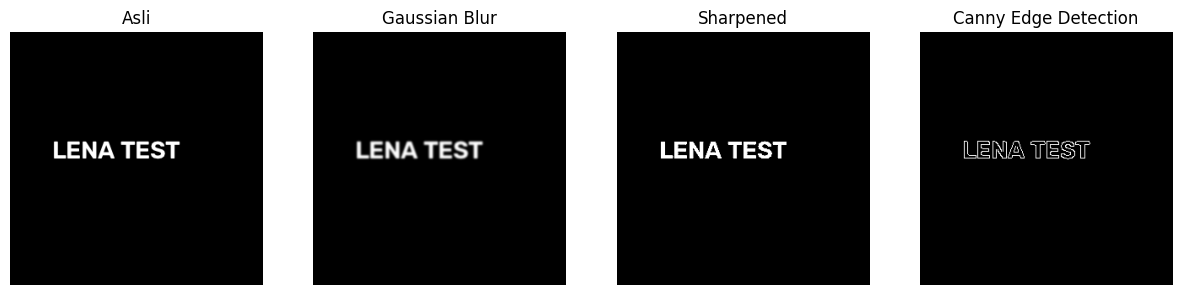

In [5]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img_item, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img_item.shape) == 2:
            plt.imshow(img_item, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(img_item, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

file_path = "/content/drive/MyDrive/Kuliah/PCVK Genap 2023/Images/lena.jpg"

if not os.path.exists(file_path):
    print(f"Peringatan: Berkas '{file_path}' tidak ditemukan.")
    print("Membuat citra dummy sementara untuk pengujian...")
    img_lena = np.zeros((300, 300, 3), dtype=np.uint8)
    cv.putText(img_lena, "LENA TEST", (50, 150), cv.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
else:
    img_lena = cv.imread(file_path)

if img_lena is not None:
    img_lena_gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
    blur = cv.GaussianBlur(img_lena, (7, 7), 1)
    edges = cv.Canny(img_lena_gray, 100, 200)
    sharpen_kernel = np.array([[0, -1, 0],
                               [-1, 5, -1],
                               [0, -1, 0]])
    sharpened = cv.filter2D(img_lena, -1, sharpen_kernel)
    show_side_by_side([img_lena, blur, sharpened, edges],
                      ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])
else:
    print("Error: Gagal membaca citra.")

Percobaan 2: Bilateral Filter & Edge Preserving Filter

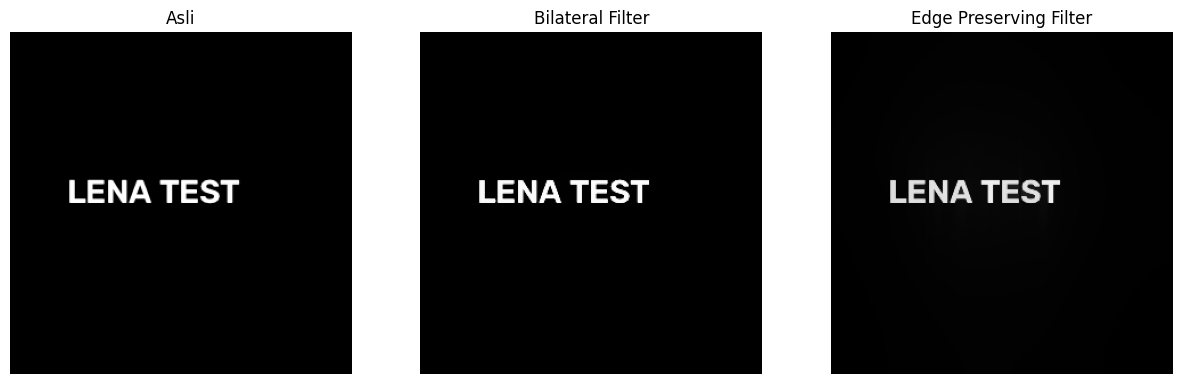

In [6]:
bilateral = cv.bilateralFilter(img_lena, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img_lena, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img_lena, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

Percobaan 3: Filtering Feature Map pada CNN

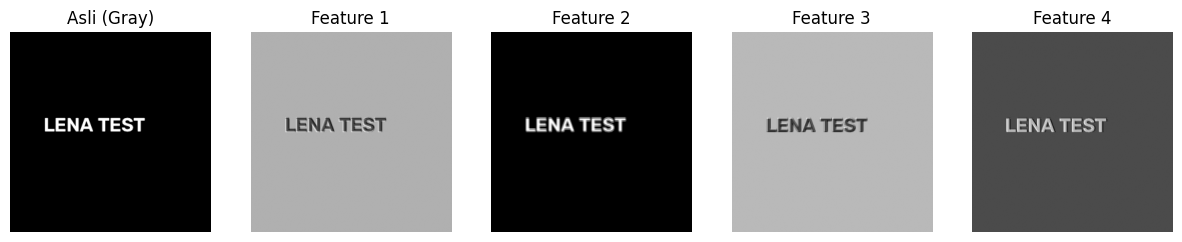

In [7]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)
    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()
img_tensor = torch.tensor(img_lena_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

with torch.no_grad():
    features = model(img_tensor)

feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_lena_gray] + feature_maps,
                  ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

Percobaan 4: Beauty Filter & Old/Vintage Filter

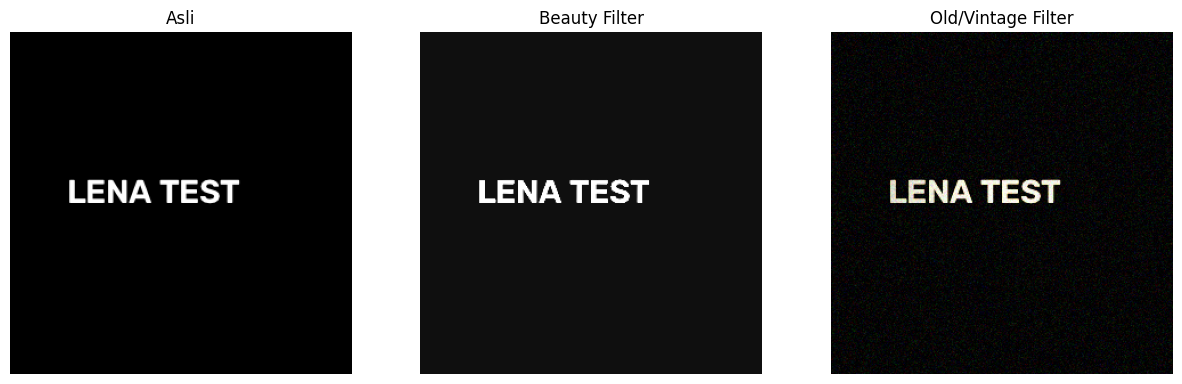

In [8]:
smooth = cv.bilateralFilter(img_lena, d=15, sigmaColor=75, sigmaSpace=75)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened_beauty = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
beauty = cv.convertScaleAbs(sharpened_beauty, alpha=1.2, beta=15)

sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img_lena, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

rows, cols = img_lena.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel_v = kernel_y * kernel_x.T
mask = kernel_v / kernel_v.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img_lena, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])

Percobaan 5: Anime / Cartoon Filter

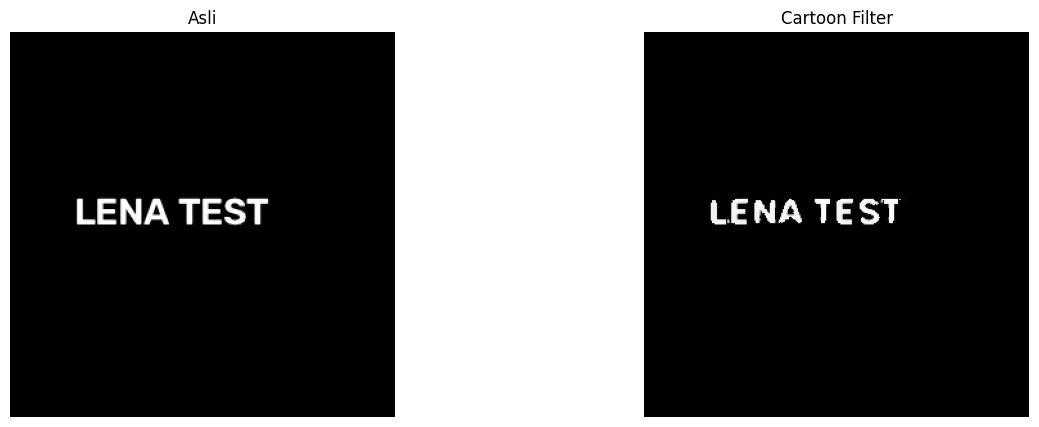

In [9]:
gray_c = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray_c, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)
color_cartoon = cv.bilateralFilter(img_lena, d=9, sigmaColor=200, sigmaSpace=200)
edges_col = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
cartoon = cv.bitwise_and(color_cartoon, edges_col)

show_side_by_side([img_lena, cartoon], ["Asli", "Cartoon Filter"])

Percobaan 6: Night Filter + Glow Effect

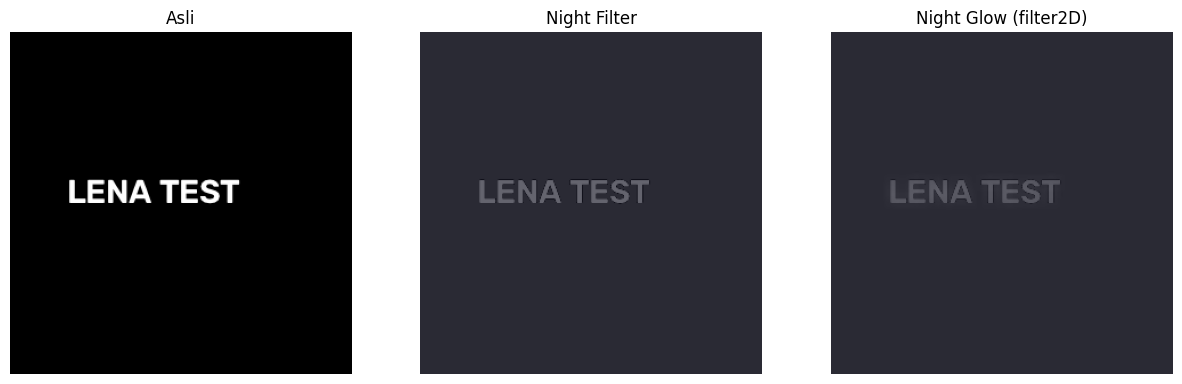

In [10]:
img_djawatan = cv.imread("/content/drive/MyDrive/Kuliah/PCVK Genap 2023/Images/djawatan.jpg")
if img_djawatan is None: img_djawatan = img_lena.copy()

night = cv.convertScaleAbs(img_djawatan, alpha=0.6, beta=-40)
blue_tint = np.full_like(night, (100, 50, 50))
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

kernel_glow = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel_glow)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img_djawatan, night, night_glow], ["Asli", "Night Filter", "Night Glow (filter2D)"])

Percobaan 7: Filter Pagi & Efek Kabut (Haze)

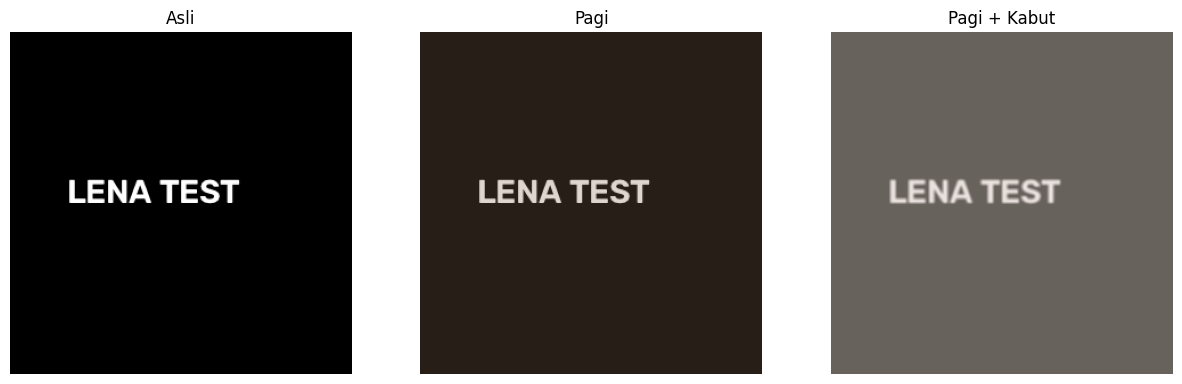

In [11]:
soft = cv.convertScaleAbs(img_djawatan, alpha=0.9, beta=20)
warm_tint = np.full_like(soft, (40, 70, 120))
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

k_g = cv.getGaussianKernel(3, 3)
kernel_kabut = k_g @ k_g.T
kabut = cv.filter2D(pagi, -1, kernel_kabut)
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img_djawatan, pagi, kabut], ["Asli", "Pagi", "Pagi + Kabut"])

F. TUGAS PRAKTIKUM

1. Tugas Analisis: Perbandingan Mean Filter vs. Median Filter pada Noise "Salt and Pepper"
  - Instruksi: Tambahkan noise bintik hitam-putih ke citra keabuan, terapkan Mean Filter ($3\times3$) dan Median Filter ($3\times3$), lalu analisis visual perbedaannya.
  - Kode Penyelesaian:

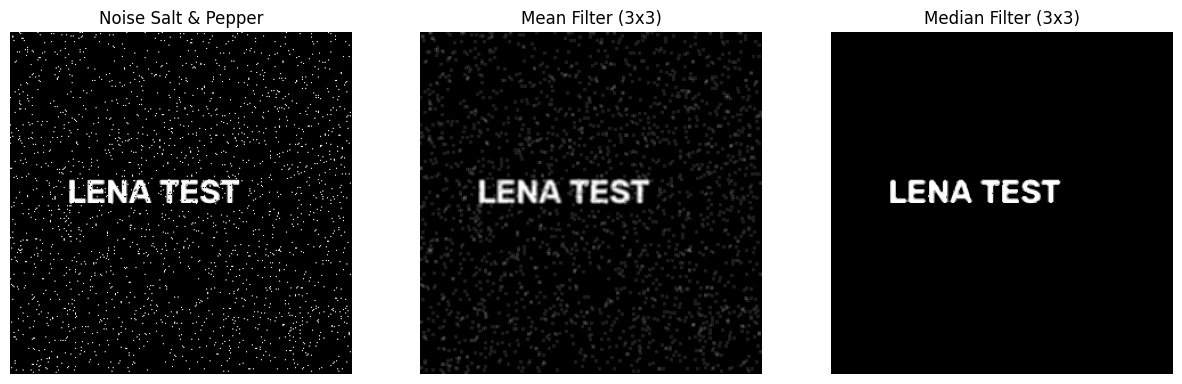

In [12]:
def add_salt_and_pepper(image, prob):
    noisy = image.copy()
    num_s = np.ceil(prob * image.size * 0.5)
    coords_s = [np.random.randint(0, i - 1, int(num_s)) for i in image.shape]
    noisy[tuple(coords_s)] = 255
    num_p = np.ceil(prob * image.size * 0.5)
    coords_p = [np.random.randint(0, i - 1, int(num_p)) for i in image.shape]
    noisy[tuple(coords_p)] = 0
    return noisy

noisy_sp = add_salt_and_pepper(img_lena_gray, 0.05)
mean_f = cv.blur(noisy_sp, (3, 3))
median_f = cv.medianBlur(noisy_sp, 3)
show_side_by_side([noisy_sp, mean_f, median_f], ["Noise Salt & Pepper", "Mean Filter (3x3)", "Median Filter (3x3)"])

2. Tugas Evaluasi: Pemilihan Ukuran Kernel Terbaik untuk Menajamkan Citra (Sharpening)
  - Instruksi: Buat kernel sharpening ukuran $3\times3$ dan $5\times5$, terapkan pada citra agak buram, lalu evaluasi aspek kejelasan tepi vs. noise distortion.
  - Kode Penyelesaian:

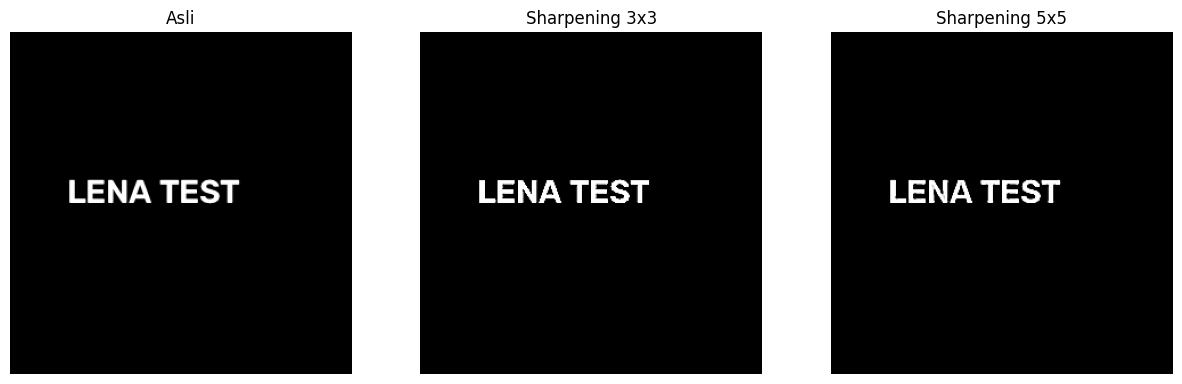

In [13]:
k_3x3 = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
k_5x5 = np.array([[-1,-1,-1,-1,-1], [-1,1,2,1,-1], [-1,2,7,2,-1], [-1,1,2,1,-1], [-1,-1,-1,-1,-1]]) / 4.0

res_3 = cv.filter2D(img_lena_gray, -1, k_3x3)
res_5 = cv.filter2D(img_lena_gray, -1, k_5x5)
show_side_by_side([img_lena_gray, res_3, res_5], ["Asli", "Sharpening 3x3", "Sharpening 5x5"])

3. Tugas Kreasi: Filter Kartun Sederhana

  - Instruksi: Buat fungsi kustom kartun(image) yang menggabungkan Bilateral Filter, deteksi tepi (Adaptive Threshold), dan penggabungan logika piksel.
  - Kode Penyelesaian:

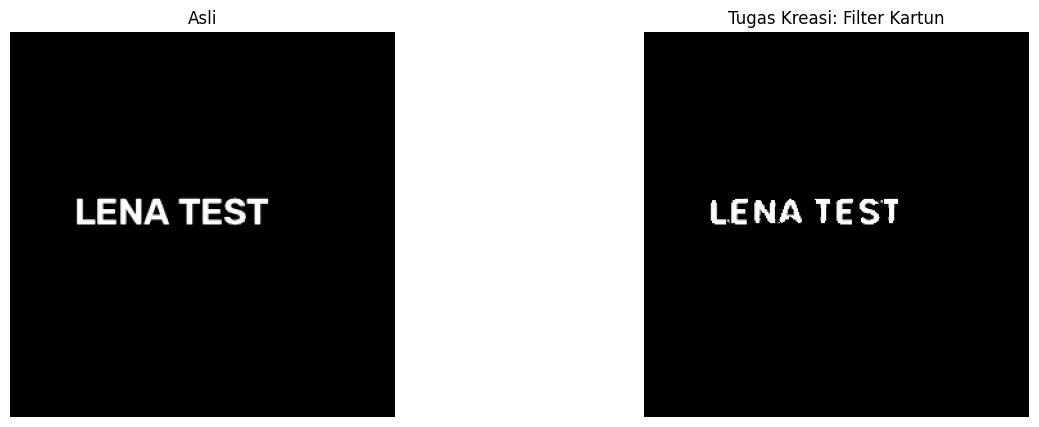

In [14]:
def kartun(image):
    color = cv.bilateralFilter(image, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 2)
    edges_col = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
    return cv.bitwise_and(color, edges_col)

res_cartoon = kartun(img_lena)
show_side_by_side([img_lena, res_cartoon], ["Asli", "Tugas Kreasi: Filter Kartun"])

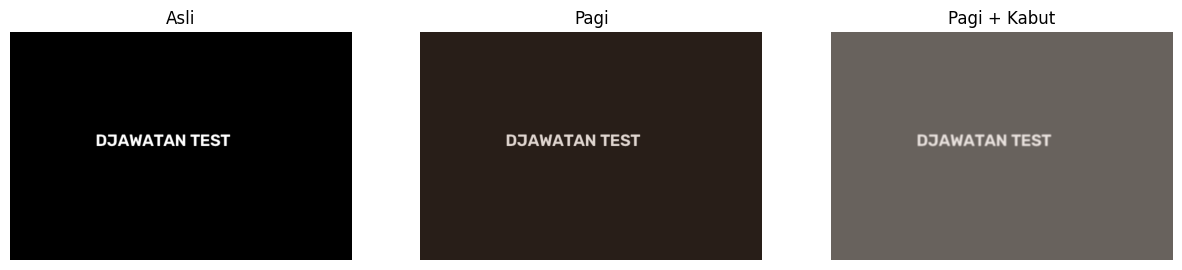

In [15]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img_item, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img_item.shape) == 2:
            plt.imshow(img_item, cmap="gray")
        else:
            plt.imshow(cv.cvtColor(img_item, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread("/content/drive/MyDrive/Kuliah/PCVK Genap 2023/Images/djawatan.jpg")
if img is None:
    img = np.zeros((400, 600, 3), dtype=np.uint8)
    cv.putText(img, "DJAWATAN TEST", (150, 200), cv.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)

alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

warm_tint = np.full_like(soft, (40, 70, 120))
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T
kabut = cv.filter2D(pagi, -1, kernel)

white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["Asli", "Pagi", "Pagi + Kabut"])

--- Hasil Tugas 1: Mean vs Median Filter ---


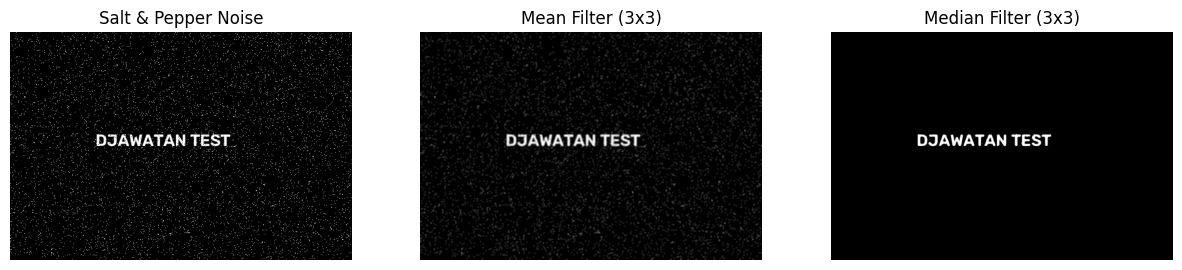

--- Hasil Tugas 2: Evaluasi Kernel Sharpening 3x3 vs 5x5 ---


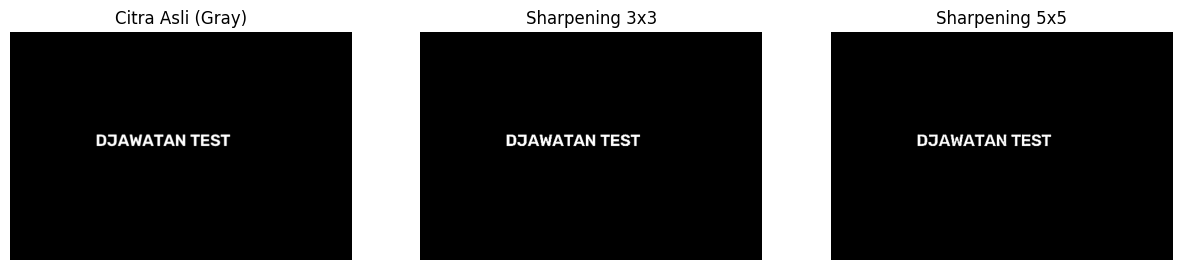

--- Hasil Tugas 3: Filter Kartun Sederhana ---


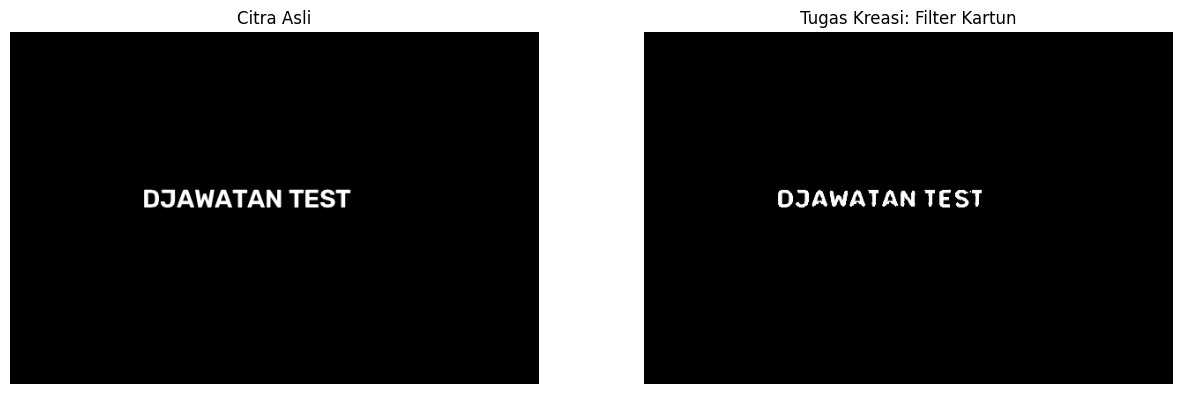

In [16]:
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY) if len(img.shape) == 3 else img.copy()

def add_salt_and_pepper(image, prob):
    noisy = image.copy()
    # Salt (Putih / 255)
    num_salt = np.ceil(prob * image.size * 0.5)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy[tuple(coords)] = 255
    # Pepper (Hitam / 0)
    num_pepper = np.ceil(prob * image.size * 0.5)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy[tuple(coords)] = 0
    return noisy

noisy_image = add_salt_and_pepper(gray_img, 0.05)

mean_filtered = cv.blur(noisy_image, (3, 3))
median_filtered = cv.medianBlur(noisy_image, 3)

print("--- Hasil Tugas 1: Mean vs Median Filter ---")
show_side_by_side([noisy_image, mean_filtered, median_filtered],
                  ["Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"])

kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]])

kernel_5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1,  1,  2,  1, -1],
                       [-1,  2,  7,  2, -1],
                       [-1,  1,  2,  1, -1],
                       [-1, -1, -1, -1, -1]]) / 4.0

sharp_3x3_res = cv.filter2D(gray_img, -1, kernel_3x3)
sharp_5x5_res = cv.filter2D(gray_img, -1, kernel_5x5)

print("--- Hasil Tugas 2: Evaluasi Kernel Sharpening 3x3 vs 5x5 ---")
show_side_by_side([gray_img, sharp_3x3_res, sharp_5x5_res],
                  ["Citra Asli (Gray)", "Sharpening 3x3", "Sharpening 5x5"])

def kartun(image_bgr):
    color = cv.bilateralFilter(image_bgr, d=9, sigmaColor=75, sigmaSpace=75)

    gray = cv.cvtColor(image_bgr, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                  cv.ADAPTIVE_THRESH_MEAN_C,
                                  cv.THRESH_BINARY, 9, 2)

    edges_colored = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
    cartoon_output = cv.bitwise_and(color, edges_colored)
    return cartoon_output

cartoon_img = kartun(img)

print("--- Hasil Tugas 3: Filter Kartun Sederhana ---")
show_side_by_side([img, cartoon_img], ["Citra Asli", "Tugas Kreasi: Filter Kartun"])